# Fine-tuning

Khi dữ liệu mới khác nhiều so với dữ liệu model từng học, vector lấy từ feature extraction có thể chưa đủ tốt. Fine-tuning là huấn luyện tiếp chính model pretrained trên dữ liệu mới. Bài này làm theo hai bước: đầu tiên giữ nguyên thân model, chỉ huấn luyện lớp cuối mới thêm vào; sau đó mở thêm các lớp của thân với learning rate nhỏ. Mỗi bước được chọn bằng điểm validation, và cuối bài kiểm xem tham số nào thực sự đã thay đổi.

> **Mục tiêu**
>
> - Thay lớp cuối và chọn phần nào của model được huấn luyện.
> - Phân biệt `requires_grad`, `train()`/`eval()` và `no_grad()`.
> - Đặt learning rate riêng cho thân model và lớp cuối; chọn checkpoint bằng validation.
> - Biết BatchNorm vẫn thay đổi dù trọng số đã bị khóa.

## Chuyển kiến thức nào sang nhiệm vụ mới?

Model pretrained gồm encoder và thường có một head phục vụ nhiệm vụ cũ. Encoder ảnh có thể học nét, cấu trúc và những tổ hợp hình dạng có ích cho nhiều nhãn khác. Nhưng head phân loại nhãn cũ không có lý do biết các nhãn mới của câu lạc bộ. Ta giữ encoder và thay head có đúng số lớp $K$ của bài mới. Cách làm này gọi là học chuyển giao (transfer learning).

Nó có ích nhất khi dữ liệu có nhãn ít mà nhiệm vụ nguồn đủ gần; ngay cả với 500 ảnh X-quang, bắt đầu từ trọng số pretrained rồi fine-tune vẫn thường tốt hơn học từ đầu.

Viết $\mathbf{z}=f_\theta(\mathbf{x})$ và logits $\boldsymbol\ell=g_\phi(\mathbf{z})$. $\theta$ là tham số encoder, $\phi$ là tham số head. Head-only training chỉ cập nhật $\phi$. Fine-tuning mở một phần hoặc toàn bộ $\theta$ cùng với $\phi$. Phần mở nhiều hơn có thể thích nghi tốt hơn nhưng cũng có thể học thuộc dữ liệu nhỏ hoặc làm mất biểu diễn có ích.



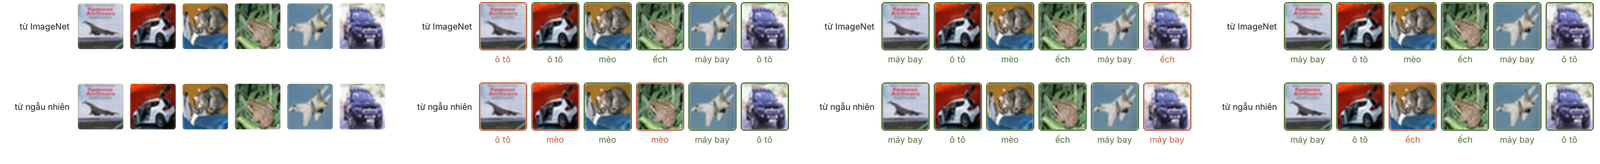

**Hỏi nhanh.** Nhiệm vụ cũ có 1000 lớp, bài mới có 3 lớp. Nạp checkpoint xong, phần nào chắc chắn phải thay hoặc kiểm trước khi train?

- A. Batch size, vì đầu ra 3 lớp cần batch chia hết cho 3
- B. Head cuối, và bảng đổi ba nhãn mới sang chỉ số 0, 1, 2
- C. Seed, vì head cũ được khởi tạo bằng một seed khác
- D. Learning rate của encoder, vì 1000 lớp cần bước nhỏ hơn

<details><summary>Đáp án</summary>

B. Head cuối, và bảng đổi ba nhãn mới sang chỉ số 0, 1, 2

Head cũ có 1000 đầu ra mang nghĩa của các nhãn cũ. Bài mới cần đúng 3 đầu ra, và một bảng cố định từ tên lớp sang chỉ số, lưu lại để đổi ngược khi nộp. Batch size không phụ thuộc số lớp. Seed và learning rate ảnh hưởng quá trình học, nhưng không sửa được một head sai kích thước và sai nghĩa.

</details>

Trong mạng lớn, các block gần input thường bắt dấu hiệu chung như nét, cạnh, mảng màu; các block sau mang đặc trưng sát nhiệm vụ cũ hơn. Vì vậy thứ tự thử thực dụng là head trước, rồi mở thêm block cuối, rồi mới đến toàn bộ, đúng ba hàng của hình trên. Khi miền đích khác hẳn nguồn, như ảnh X-quang so với ảnh đời thường, đặc trưng ở các block đầu cũng có thể cần đổi; mỗi mức mở khi đó là một thí nghiệm, và baseline head-only là mốc để biết thay đổi có đáng giá.

**Hỏi nhanh.** Dữ liệu đích ít và khá giống miền nguồn, head-only đã có điểm validation. Ngân sách chỉ đủ thử thêm một cấu hình. Nên thử gì?

- A. Mở toàn bộ mạng, với cùng learning rate của head
- B. Khởi tạo lại encoder rồi học từ đầu trên dữ liệu đích
- C. Mở block đầu gần input, vì đặc trưng nền quan trọng nhất
- D. Mở thêm block cuối, giữ các block đầu đóng băng

<details><summary>Đáp án</summary>

D. Mở thêm block cuối, giữ các block đầu đóng băng

Block cuối gần với nhiệm vụ cũ nhất, nên thường là phần cần thích nghi trước. Block đầu giữ những dấu hiệu chung, mà dữ liệu đích ít thì khó học lại tốt hơn. Mở toàn bộ với bước lớn như head dễ kéo encoder ra khỏi biểu diễn đã học khi dữ liệu ít. Học từ đầu là bỏ đi chính lợi thế của trọng số pretrained.

</details>

## Một mô hình nguồn tự pretrain

Để thấy mọi bước mà không cần tải trọng số, ta tự tạo một mô hình nguồn ngay trong notebook từ bộ chữ số $8\times8$ của scikit-learn. Nhiệm vụ nguồn phân loại các chữ số 0–7; nhiệm vụ đích phân biệt 8 và 9. Mọi ảnh 8 hoặc 9 đều bị loại khỏi việc học nguồn, nên encoder nguồn đóng đúng vai một checkpoint pretrained: đã học đặc trưng hữu ích trên dữ liệu khác và chưa từng thấy nhãn đích.

Với ResNet hay DistilBERT, các bước phía sau giống hệt; chỉ khác ở chỗ trọng số được nạp từ tệp checkpoint thay vì vừa học xong.

Một encoder `64 → 32 → ReLU` đủ để thực nghiệm chạy trong vài giây. Pixel của bộ dữ liệu này nằm từ 0 đến 16, nên input được chia 16; mọi bước sau, kể cả nhiệm vụ đích, phải dùng đúng phép chia ấy, giống như fine-tune một checkpoint thật phải dùng đúng processor của nó (bài 4.1). Một phần ảnh nguồn được giữ làm validation để kiểm encoder thực sự đã học, thay vì gọi trọng số ngẫu nhiên là “đã học”.

In [ ]:
import copy
import numpy as np
import torch
from torch import nn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

torch.set_num_threads(1)
torch.manual_seed(3)
digits = load_digits()
source_ids = np.flatnonzero(digits.target < 8)
target_ids = np.flatnonzero(digits.target >= 8)
source_train, source_valid = train_test_split(
    source_ids, test_size=0.25, stratify=digits.target[source_ids], random_state=3
)

def inputs(ids):
    return torch.tensor(digits.data[ids] / 16.0, dtype=torch.float32)

source_encoder = nn.Sequential(nn.Linear(64, 32), nn.ReLU())
source_head = nn.Linear(32, 8)
source_model = nn.Sequential(source_encoder, source_head)
source_optimizer = torch.optim.Adam(source_model.parameters(), lr=0.01)
criterion = nn.CrossEntropyLoss()
source_x = inputs(source_train)
source_y = torch.tensor(digits.target[source_train], dtype=torch.long)
for _ in range(80):
    source_model.train()
    source_optimizer.zero_grad(set_to_none=True)
    loss = criterion(source_model(source_x), source_y)
    loss.backward()
    source_optimizer.step()

source_model.eval()
with torch.no_grad():
    source_prediction = source_model(inputs(source_valid)).argmax(dim=1).numpy()
print("source train/valid:", len(source_train), len(source_valid))
print("source valid accuracy:", round(float((source_prediction == digits.target[source_valid]).mean()), 4))
print("source gap target:", len(set(source_ids) & set(target_ids)) == 0)

source train/valid: 1082 361
source valid accuracy: 0.9806
source gap target: True


Accuracy 0.9806 trên 361 ảnh nguồn giữ lại cho thấy encoder đã học được đặc trưng chữ số có ích. Dòng thứ ba xác nhận không ảnh 8 hay 9 nào lọt vào việc học nguồn; nếu có, điểm của nhiệm vụ đích sau này sẽ đo cả phần encoder đã thuộc lòng, không chỉ phần kiến thức được chuyển.

Split ở đây chia theo từng ảnh; với dữ liệu có nhiều ảnh của cùng một người hay cùng một buổi, split phải chia theo nhóm ấy (bài 1.3).

**Hỏi nhanh.** Một đội pretrain encoder trên toàn bộ 1797 ảnh chữ số từ 0 đến 9 cùng nhãn của chúng, rồi báo accuracy của nhiệm vụ phân biệt 8 với 9 trên validation lấy từ chính bộ ảnh ấy. Con số này đo gì?

- A. Đúng khả năng chuyển học, vì head đích vẫn là head mới
- B. Đúng khả năng chuyển học, vì phần nguồn không dùng head đích
- C. Một con số quá lạc quan, vì encoder đã học cả ảnh validation
- D. Một con số quá bi quan, vì nhãn 0 đến 7 làm nhiễu encoder

<details><summary>Đáp án</summary>

C. Một con số quá lạc quan, vì encoder đã học cả ảnh validation

Encoder đã thấy ảnh validation, thậm chí đã học tách 8 khỏi 9 bằng nhãn thật của chúng. Head mới chỉ cần đọc lại một phép tách có sẵn. Head mới hay cũ không thay đổi được việc encoder đã thấy dữ liệu đánh giá. Nhãn 0 đến 7 không làm hại, chúng chính là phần kiến thức muốn chuyển. Bài này loại hết ảnh 8 và 9 khỏi phần nguồn để tránh đúng lỗi ấy.

</details>

## Bắt đầu bằng một head mới

Ta dành 48 ảnh đích làm train có nhãn; các ảnh đích còn lại làm validation. Nhãn 8 đổi thành 0, nhãn 9 đổi thành 1 để khớp head hai lớp. Việc đổi nhãn phải lưu lại để trả output đúng tên lớp sau khi dự đoán.

In [ ]:
target_train, target_valid = train_test_split(
    target_ids, train_size=48, random_state=5, stratify=digits.target[target_ids]
)
target_x = inputs(target_train)
target_y = torch.tensor(digits.target[target_train] - 8, dtype=torch.long)
valid_x = inputs(target_valid)
valid_y = torch.tensor(digits.target[target_valid] - 8, dtype=torch.long)

torch.manual_seed(10)
initial_head = nn.Linear(32, 2)
head_only = nn.Sequential(copy.deepcopy(source_encoder), copy.deepcopy(initial_head))
for parameter in head_only[0].parameters():
    parameter.requires_grad_(False)
optimizer = torch.optim.SGD(head_only[1].parameters(), lr=0.05)
before = {name: value.detach().clone() for name, value in head_only[0].named_parameters()}

head_only.train()
head_only[0].eval()
optimizer.zero_grad(set_to_none=True)
loss = criterion(head_only(target_x), target_y)
loss.backward()
print("encoder grad None:", all(p.grad is None for p in head_only[0].parameters()))
print("head co gradient:", head_only[1].weight.grad.norm().item() > 0)
optimizer.step()
print("encoder khong doi:", all(torch.equal(before[n], p) for n, p in head_only[0].named_parameters()))
print("target train/valid:", len(target_train), len(target_valid))

encoder grad None: True
head co gradient: True
encoder khong doi: True
target train/valid: 48 306


Ở mạng này, encoder chỉ có Linear và ReLU; `eval()` chưa đổi phép tính của nó. Ta vẫn gọi để tạo thói quen đúng khi sau này dùng encoder có Dropout hoặc BatchNorm.

Dòng `encoder grad None` kiểm việc không tạo gradient cho tham số đã đóng băng. Dòng thứ ba so từng giá trị tensor trước và sau một bước, kiểm việc optimizer không sửa encoder. Nếu chỉ nhìn loss giảm, ta không biết phần nào đã được cập nhật.

Đóng băng nghĩa là đặt `requires_grad_(False)` cho tham số encoder: chúng không nhận gradient và optimizer không sửa. Số tham số được học khi đó chỉ là của head, đếm bằng `sum(p.numel() for p in model.parameters() if p.requires_grad)`: ResNet-18 đóng băng hết rồi thay `fc` bằng `Linear(512, 10)` còn $512 \cdot 10 + 10 = 5130$; ResNet-50 với head $2048 \to K$ là $2048K + K$.

**Hỏi nhanh.** Một tham số có `requires_grad=False` nhưng vẫn nằm trong forward. Khi dự đoán, nó đóng vai trò gì?

- A. Vẫn tính forward như cũ, chỉ không được học
- B. Bị bỏ qua, nên output của tầng ấy bằng 0
- C. Bị thay bằng giá trị trung bình của nó
- D. Bị tách khỏi mạng cho tới khi gọi lại `train()`

<details><summary>Đáp án</summary>

A. Vẫn tính forward như cũ, chỉ không được học

Đóng băng chỉ tắt việc tính gradient cho tham số, nên optimizer không có gì để cập nhật nó, còn phép forward thì không đổi. Encoder đóng băng vẫn tính ra đặc trưng $\mathbf z$, và chính nhờ thế mà kiến thức của phần nguồn đi được vào head. Không có cơ chế nào thay tham số bằng 0 hay bằng giá trị khác. `train()` chỉ đổi chế độ của các tầng.

</details>

**Hỏi nhanh.** Head hai lớp được học với nhãn `digit - 8`. Validation accuracy đạt 0.94, nhưng file nộp ghi thẳng `argmax` của logits và được chấm 0 điểm. Lỗi khả dĩ nhất là gì?

- A. Head hai lớp không đủ sức cho dữ liệu test
- B. Validation bị rò, nên 0.94 là con số ảo
- C. File nộp ghi chỉ số 0, 1 thay vì 8, 9
- D. Encoder ở chế độ `eval()` khi dự đoán test

<details><summary>Đáp án</summary>

C. File nộp ghi chỉ số 0, 1 thay vì 8, 9

Đáp án là 8 hoặc 9, còn `argmax` trả về chỉ số 0 hoặc 1, nên không dòng nào khớp. Head yếu hay validation bị rò thì điểm tụt, nhưng với hai lớp cân bằng, đoán bừa cũng được khoảng 0.5, khó mà ra đúng 0. Sửa bằng cách cộng lại 8, hoặc tra bảng đổi chỉ số ra tên lớp đã lưu, trước khi ghi file. Gọi `eval()` khi dự đoán là đúng.

</details>

## Vì sao encoder dùng bước nhỏ hơn

Xét mô hình một chiều $\hat y=a(wx)$, encoder có tham số $w$, head có tham số $a$, loss $L=(\hat y-y)^2$. Với $x=1$, $w=2$, $a=1$, $y=3$, ta có $\hat y=2$, phần dư $-1$, nên

$$\frac{\partial L}{\partial a}=2(-1)\cdot2=-4,\qquad \frac{\partial L}{\partial w}=2(-1)\cdot1=-2.$$

Nếu learning rate head là 0.1, encoder là 0.01, cập nhật cho $a=1.4$ và $w=2.02$. Nếu encoder đóng băng thì $w$ vẫn bằng 2.



In [ ]:
x, w, a, y = 1.0, 2.0, 1.0, 3.0
residual = a * w * x - y
grad_a = 2 * residual * w * x
grad_w = 2 * residual * a * x
print("gradient:", grad_a, grad_w)
print("sau buoc:", a - 0.1 * grad_a, w - 0.01 * grad_w)

gradient: -4.0 -2.0
sau buoc: 1.4 2.02


Để ý $\partial L/\partial w$ chứa $a$: gradient về encoder phải đi qua head. Head mới khởi tạo ngẫu nhiên, nên trong những bước đầu, hướng gradient mà encoder nhận được cũng mang theo sự ngẫu nhiên đó. Nếu encoder đi bước lớn như head, nó có thể bị kéo xa chỉ để bù cho một head còn sai, làm hỏng những đặc trưng tốt đã học. Việc mô hình mất dần kiến thức nguồn khi được huấn luyện tiếp cho nhiệm vụ mới gọi là quên thảm khốc (catastrophic forgetting); bước lớn ở phần pretrained làm hiện tượng này đến nhanh hơn.

Hai cách hạn chế: learning rate nhỏ cho encoder, hoặc học head-only vài epoch rồi mới mở encoder. Tỉ lệ 10 lần ở ví dụ là một lựa chọn, không phải hằng số. Với BERT, bài báo gốc fine-tune toàn bộ mô hình với learning rate từ $2\cdot10^{-5}$ đến $5\cdot10^{-5}$ trong 2–4 epoch, nhỏ hơn mức $10^{-4}$ dùng khi pretrain chính BERT.

**Hỏi nhanh.** Vẫn ví dụ ấy, với $x = 1$, $w = 2$, $y = 3$, nhưng head mới được khởi tạo $a = -1$. Gradient theo $w$ bằng bao nhiêu, và gradient descent đẩy $w$ theo hướng nào?

- A. $-2$, nên $w$ tăng, như ví dụ có $a = 1$
- B. $-10$, nên $w$ tăng để $\hat y$ lớn lên
- C. $0$, nên $w$ đứng yên chờ head học xong
- D. $10$, nên $w$ giảm

<details><summary>Đáp án</summary>

D. $10$, nên $w$ giảm

$\hat y = awx = -2$, phần dư là $-5$, nên $\partial L/\partial w = 2(-5)\cdot a\cdot x = 2(-5)(-1) = 10$, và $w$ giảm. Với $a = -1$, giảm $w$ đúng là làm $\hat y = -w$ tăng, nên loss giảm. Nhưng encoder đang bị sửa để bù cho một head sai dấu, trong khi cách sửa đúng là đổi dấu $a$. Ra $-2$ là quên rằng gradient theo $w$ nhân với $a$. Ra $-10$ là nhầm dấu. Gradient theo $w$ chỉ bằng 0 khi $a = 0$.

</details>

## So sánh head-only và mở encoder

Hai thực nghiệm bắt đầu từ cùng encoder nguồn và cùng head mới, nên khác biệt chỉ nằm ở việc mở encoder. Ta chạy 60 epoch full-batch, chấm validation sau mỗi epoch và giữ checkpoint có validation loss thấp nhất. Head dùng learning rate 0.05; khi mở, encoder có nhóm riêng với 0.003, nhỏ hơn khoảng 17 lần. Vì validation vừa dùng để chọn epoch vừa để so hai mode, con số báo cáo cuối cùng nên lấy từ một test giữ kín.

In [ ]:
def run_transfer(open_encoder):
    transferred = nn.Sequential(copy.deepcopy(source_encoder), copy.deepcopy(initial_head))
    for parameter in transferred[0].parameters():
        parameter.requires_grad_(open_encoder)
    groups = [{"params": transferred[1].parameters(), "lr": 0.05}]
    if open_encoder:
        groups.append({"params": transferred[0].parameters(), "lr": 0.003})
    optimizer = torch.optim.Adam(groups)
    best_loss = float("inf")
    best_state, best_epoch = None, None
    history = []
    for epoch in range(1, 61):
        transferred.train()
        if not open_encoder:
            transferred[0].eval()
        optimizer.zero_grad(set_to_none=True)
        train_loss = criterion(transferred(target_x), target_y)
        train_loss.backward()
        optimizer.step()
        transferred.eval()
        with torch.no_grad():
            val_loss = criterion(transferred(valid_x), valid_y).item()
        history.append((train_loss.item(), val_loss))
        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(transferred.state_dict())
    transferred.load_state_dict(best_state)
    with torch.no_grad():
        accuracy = (transferred(valid_x).argmax(dim=1) == valid_y).float().mean().item()
    trainable = sum(p.numel() for p in transferred.parameters() if p.requires_grad)
    return transferred, history, best_epoch, best_loss, accuracy, trainable

for opened in [False, True]:
    net, history, epoch, val_loss, accuracy, count = run_transfer(opened)
    print("open encoder =", opened, "| trainable =", count, "| best epoch =", epoch)
    print("best val loss =", round(val_loss, 4),
          "| epoch 60 val loss =", round(history[-1][1], 4),
          "| val accuracy =", round(accuracy, 4))

open encoder = False | trainable = 66 | best epoch = 36
best val loss = 0.2247 | epoch 60 val loss = 0.2366 | val accuracy = 0.902
open encoder = True | trainable = 2146 | best epoch = 60
best val loss = 0.157 | epoch 60 val loss = 0.157 | val accuracy = 0.9379


Đọc loss và accuracy ở checkpoint được chọn, không chỉ ở epoch cuối:

- **Head-only** học 66 tham số ($32\cdot2+2$); validation loss thấp nhất 0.2247 ở epoch 36, đến epoch 60 là 0.2366 trong khi train loss vẫn giảm. Giữ checkpoint epoch 36 nghĩa là không phải trả giá cho 24 epoch học thêm vô ích.
- **Mở encoder** học 2146 tham số (thêm $64\cdot32+32=2080$ của encoder), loss 0.1570 và accuracy 0.9379, so với 0.9020 của head-only: đúng thêm 11 trong 306 ảnh validation. Checkpoint tốt nhất của nó rơi đúng epoch cuối, tức validation còn đang giảm; ngân sách 60 epoch có thể chưa đủ, và đó là tín hiệu để chạy dài hơn, không phải bằng chứng đã hội tụ.

Trên một split nhỏ, chênh lệch 11 ảnh là bằng chứng có ích, chưa phải định luật “mở encoder luôn thắng”. Loss và accuracy cũng có thể chọn hai epoch khác nhau: cross-entropy còn phạt sự tự tin sai, còn accuracy chỉ nhìn argmax.

Ở đây encoder chỉ có một tầng Linear nên mở nó là mở toàn bộ; với ResNet, “mở block cuối” là một tập tham số riêng, có số lượng và bộ nhớ riêng phải đo lại. Mỗi tham số được mở kéo theo một gradient và, với Adam, hai moment $m$, $v$: thêm ba số float32 cho mỗi tham số, chưa kể activation phải giữ để backward qua phần mở (bài 3.7). Với 66 tham số, phần này không đáng kể; với hàng chục triệu tham số, nó lên tới hàng trăm MB.







**Hỏi nhanh.** Một lần fine-tune 20 epoch có checkpoint tốt nhất ở epoch 20, và validation loss vẫn đang giảm. Hiểu kết quả này thế nào?

- A. Có thể chưa đủ epoch, nên chạy thêm rồi xem tiếp
- B. Đã hội tụ đúng ở epoch 20, nên dừng tại đó
- C. Đã overfit, vì điểm tốt nhất rơi vào epoch cuối
- D. Chọn lại theo train loss, vì validation chưa ổn

<details><summary>Đáp án</summary>

A. Có thể chưa đủ epoch, nên chạy thêm rồi xem tiếp

Validation còn giảm ở epoch cuối nghĩa là chưa thấy điểm mà từ đó mô hình tệ đi. Chạy thêm có thể cho checkpoint tốt hơn, còn nếu không thì cơ chế giữ checkpoint tốt nhất vẫn bảo vệ ta. Muốn kết luận đã hội tụ hay đã overfit thì phải thấy validation dừng giảm hoặc tăng lên. Train loss gần như luôn giảm theo thời gian học, nên không dùng để chọn checkpoint. Thực nghiệm mở encoder của bài có đúng hình dạng này.

</details>

[Script của chương](recipes/README.md) đưa đúng thí nghiệm này lên DistilBERT với model và dữ liệu lưu sẵn trên máy. Mode `head` đóng băng backbone và giữ nó ở eval; mode `full` học backbone với learning rate $10^{-5}$ và head với $10^{-3}$. Cả hai chọn checkpoint theo macro-F1 validation và ghi số tham số học, lịch sử validation, thời gian vào `RESULT.json`; so hai tệp ấy giống như so hai cặp dòng output trên.

## Freeze, eval và BatchNorm là ba chuyện

BatchNorm (bài 3.6) có tham số affine như weight và bias, đồng thời có buffer `running_mean`, `running_var`. Trong train mode, batch mới có thể cập nhật buffer dù không tính gradient; chuyển sang eval thì dùng buffer đã tích lũy. Với encoder cần giữ cố định, ta giữ cả buffer bằng eval.

Khi batch fine-tune nhỏ, như vài ảnh độ phân giải cao mỗi batch, thống kê batch rất nhiễu, nên nhiều hệ thống phát hiện vật thể giữ BatchNorm của backbone cố định ngay cả khi các trọng số khác được học.

Thí nghiệm sau đặt mọi tham số BatchNorm thành không học, nhưng vẫn cho một batch qua train mode. Trung bình batch là $(3,6)$, `momentum=0.5`, trung bình cũ là $(0,0)$, nên trung bình mới là $(1.5,3)$. Trong BatchNorm, momentum này là hệ số cập nhật thống kê, khác nghĩa với momentum của optimizer.

In [ ]:
bn = nn.BatchNorm1d(2, momentum=0.5)
for parameter in bn.parameters():
    parameter.requires_grad_(False)
batch = torch.tensor([[2., 4.], [4., 8.]])
bn.train()
with torch.no_grad():
    bn(batch)
after_train = bn.running_mean.clone()
bn.eval()
with torch.no_grad():
    bn(batch + 100)
print("running mean sau train:", after_train.tolist())
print("eval giu buffer:", torch.equal(after_train, bn.running_mean))
print("khop tinh tay:", torch.allclose(after_train, batch.mean(dim=0) * 0.5))

running mean sau train: [1.5, 3.0]
eval giu buffer: True
khop tinh tay: True




Dòng đầu trực tiếp phản bác hiểu lầm “không có gradient thì không có gì thay đổi”. Dropout lại không có running mean; eval làm nó bỏ thao tác che ngẫu nhiên. Khi gọi `model.train()` ở đầu epoch, các module con cũng chuyển train; nếu encoder phải đứng yên, gọi `encoder.eval()` sau đó. Còn `no_grad()` không được bọc phần đang học (head, adapter): autograd phải ghi lại các phép tính ấy thì backward mới tới được tham số của chúng.

**Hỏi nhanh.** Đóng băng weight và bias của BatchNorm, rồi cho một batch mới đi qua ở chế độ `train()`, bên trong `no_grad()`. Running mean có đổi không?

- A. Không, vì mọi tham số đều có `requires_grad=False`
- B. Không, vì `no_grad()` chặn mọi thay đổi trong forward
- C. Có, vì buffer tự cập nhật ngay trong forward
- D. Có, nhưng chỉ khi gọi `optimizer.step()` sau đó

<details><summary>Đáp án</summary>

C. Có, vì buffer tự cập nhật ngay trong forward

Running mean là buffer, không phải tham số. BatchNorm ở chế độ train tự cập nhật nó ngay trong forward bằng momentum, không cần gradient hay optimizer. `requires_grad` và `no_grad()` chỉ điều khiển autograd. Thí nghiệm ở trên đã đổi running mean thành $(1.5, 3)$ khi chưa có bước optimizer nào.

</details>

**Hỏi nhanh.** `model = nn.Sequential(encoder, head)`, và encoder có BatchNorm cần giữ nguyên. Đoạn sau có giữ được running mean của encoder không?
```py
encoder.eval()            # gọi một lần trước vòng lặp
for epoch in range(10):
    model.train()
    for x, y in loader:
        ...               # forward, backward, step cho head
```

- A. Có, vì `encoder.eval()` đã được gọi từ trước
- B. Không, vì `model.train()` lan xuống cả encoder
- C. Có, nếu tham số của encoder đã `requires_grad=False`
- D. Không, vì optimizer cập nhật buffer ở mỗi `step()`

<details><summary>Đáp án</summary>

B. Không, vì `model.train()` lan xuống cả encoder

`model.train()` gọi `train()` cho mọi module con, nên ngay từ epoch đầu encoder đã ở chế độ train, và BatchNorm cập nhật buffer ở mỗi batch. Sửa bằng cách gọi `encoder.eval()` ngay sau `model.train()` trong mỗi epoch. `requires_grad=False` không giữ được buffer, như thí nghiệm vừa rồi cho thấy. Optimizer cũng không chạm tới buffer.

</details>

## Khi đi thi

- Học head trên encoder đóng băng trước, để có mốc so sánh và một bài nộp hợp lệ.
- Phần pretrained dùng learning rate nhỏ; model cỡ BERT thường từ $2\cdot10^{-5}$ đến $5\cdot10^{-5}$.
- Dùng đúng processor của checkpoint: kích thước ảnh, mean/std, tokenizer.

## Tóm tắt

- Fine-tuning học tiếp model pretrained trên nhiệm vụ mới, với head mới đúng số lớp.
- Bắt đầu bằng head-only trên encoder đóng băng; rồi mở thêm encoder với learning rate nhỏ hơn head, chọn checkpoint bằng validation.
- Đóng băng tham số, chế độ train/eval, `no_grad()` và tập tham số của optimizer là bốn công tắc khác nhau; BatchNorm còn có buffer đổi ngay trong forward ở chế độ train.
- Trên ví dụ chữ số, mở encoder nâng validation accuracy từ 0.9020 lên 0.9379.

## Kiểm tra cuối bài

**Câu 1.** Một đội có 3000 bình luận tiếng Anh gán ba nhãn cảm xúc, và một GPU dùng trong hai giờ. Nên xuất phát từ đâu?

- A. BERT pretrained, thay head ba lớp rồi fine-tune nhẹ
- B. Transformer cỡ BERT khởi tạo ngẫu nhiên, học từ đầu trên 3000 câu
- C. ResNet-50 pretrained trên ImageNet, thay head ba lớp rồi fine-tune
- D. AlexNet học từ đầu trên vector đếm từ của 3000 bình luận

<details><summary>Đáp án</summary>

A. BERT pretrained, thay head ba lớp rồi fine-tune nhẹ

BERT đã được pretrain trên một lượng lớn văn bản tiếng Anh, nên biểu diễn của nó chuyển tốt sang bài phân loại cảm xúc. Chỉ cần một head mới và vài epoch với learning rate nhỏ. Cùng kiến trúc mà khởi tạo ngẫu nhiên thì 3000 câu quá ít để học lại cả một ngôn ngữ. ResNet-50 học đặc trưng của ảnh, không có gì về từ ngữ để chuyển. AlexNet là mạng cho ảnh, và học từ đầu cũng bỏ mất lợi thế của pretrained.
Phỏng theo: [NOAI 2025 Singapore · Phần 1 · Câu 17](https://learn.aisingapore.org/wp-content/uploads/2025/10/NOAI-2025-MCQ-Assessment-Questions.pdf#page=3)

</details>

**Câu 2.** Ta muốn giữ cố định encoder khi học head, đồng thời tiết kiệm bộ nhớ và thời gian của backward. Cách nào đạt được cả hai?

- A. Đặt learning rate 0 cho nhóm tham số của encoder
- B. Gọi `requires_grad_(False)` cho các tham số của encoder
- C. Gọi `encoder.eval()` trước mỗi epoch train
- D. Gọi `model.freeze()` một lần trước vòng lặp train

<details><summary>Đáp án</summary>

B. Gọi `requires_grad_(False)` cho các tham số của encoder

Tham số có `requires_grad=False` thì autograd không tính và không lưu gradient, nên backward dừng ở head, và optimizer không có gì để cập nhật ở encoder. Learning rate 0 giữ trọng số không đổi, nhưng gradient của encoder vẫn được tính và lưu, tốn đúng phần bộ nhớ và thời gian muốn tiết kiệm. `eval()` chỉ đổi cách Dropout và BatchNorm hoạt động, tham số vẫn được học. `nn.Module` không có phương thức `freeze()`, dòng ấy báo `AttributeError`.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 132](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=50)

</details>

**Câu 3.** Ba đội cùng dùng một BERT pretrained cho bài phân loại. Đội A viết prompt kèm 5 ví dụ có nhãn. Đội B đóng băng BERT, học một head mới trên vector `[CLS]`. Đội C cập nhật cả trọng số BERT lẫn head trên 2000 câu có nhãn. Đội nào đã làm thay đổi trọng số pretrained?

- A. Cả ba đội, vì đều dùng dữ liệu có nhãn của bài
- B. Chỉ đội C
- C. Đội B và đội C, vì cả hai đều huấn luyện
- D. Đội A và đội C, vì cả hai đều đưa ví dụ vào mô hình

<details><summary>Đáp án</summary>

B. Chỉ đội C

Chỉ đội C cập nhật $\theta$ của encoder, và đó là fine-tuning theo nghĩa của bài. Đội B có huấn luyện, nhưng chỉ học $\phi$ của head mới, còn mọi trọng số pretrained giữ nguyên, đúng là mốc head-only. Đội A không huấn luyện gì: ví dụ trong prompt chỉ là input của một lần forward, xong lượt dự đoán thì mô hình vẫn y như cũ.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 245](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=88)

</details>

**Câu 4.** Fine-tune ResNet-50 pretrained cho 10 lớp:
```py
model = resnet50(weights="IMAGENET1K_V2")
for p in model.parameters():
    p.requires_grad = False
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
model.fc = nn.Linear(2048, 10)
# vòng train: zero_grad, forward, loss.backward(), optimizer.step()
```
Sau khi train, validation accuracy chỉ khoảng 10%, và `model.fc.weight` giống hệt lúc khởi tạo. Lỗi ở đâu?

- A. Optimizer được tạo trước khi thay `fc`, nên không chứa `fc` mới
- B. Backbone đóng băng chặn gradient, không cho đi tới `fc`
- C. Learning rate 1e-3 quá nhỏ cho một head khởi tạo ngẫu nhiên
- D. Optimizer nhận tham số đóng băng nên bỏ qua cả nhóm

<details><summary>Đáp án</summary>

A. Optimizer được tạo trước khi thay `fc`, nên không chứa `fc` mới

Optimizer chỉ giữ danh sách tham số có ở lúc nó được tạo, tức `fc` cũ. `fc` mới có `requires_grad=True` và có gradient sau `backward()`, nhưng không nằm trong nhóm nào, nên `step()` không đụng tới. Head ngẫu nhiên không học, nên accuracy chỉ ngang đoán bừa. Sửa bằng cách thay head trước, rồi tạo optimizer với `model.fc.parameters()`. Gradient tới `fc` không cần đi qua backbone, vì `fc` đứng sau backbone. Learning rate nhỏ thì trọng số vẫn đổi, không thể giữ nguyên từng giá trị. Optimizer bỏ qua từng tham số có `grad` bằng `None`, chứ không bỏ cả nhóm.
Phỏng theo: [NOAI 2026 Singapore · Chung kết · Câu 15](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Final-Assessment-Section-1-MCQs-Google-Forms.pdf#page=22)

</details>

**Câu 5.** Fine-tune BERT-base phân loại 5 lớp trên vài nghìn câu: batch 32, `max_length=128`, AdamW với learning rate $10^{-3}$ cho toàn bộ mô hình, 3 epoch. Validation loss giảm sau epoch 1 rồi tăng mạnh, còn train loss vẫn giảm đều. Nguyên nhân khả dĩ nhất là gì?

- A. Batch 32 quá nhỏ, cần gradient accumulation lên 256
- B. `max_length=128` cắt mất chữ, cần tăng lên 512 token
- C. Thiếu warmup, thêm warmup là đủ, giữ learning rate cũ
- D. Learning rate quá lớn đối với trọng số pretrained

<details><summary>Đáp án</summary>

D. Learning rate quá lớn đối với trọng số pretrained

$10^{-3}$ lớn hơn 20 đến 50 lần so với dải $2\cdot 10^{-5}$ đến $5\cdot 10^{-5}$ mà bài báo BERT dùng. Mỗi bước kéo trọng số pretrained đi rất xa, mô hình nhanh chóng thuộc lòng train và mất biểu diễn tổng quát, đúng hình dạng train giảm, validation tăng sau epoch đầu. Sửa bằng cách giảm learning rate về dải ấy, giữ checkpoint epoch 1, và dừng sớm. Warmup chỉ làm mềm các bước đầu; hết warmup, learning rate vẫn là $10^{-3}$. Batch 32 là cỡ thường dùng khi fine-tune BERT. Cắt ở 128 token làm mất thông tin như nhau ở mọi epoch, không tạo ra việc validation tăng lên sau epoch 1.
Phỏng theo: [NOAI 2026 Singapore · Chung kết · Câu 21](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Final-Assessment-Section-1-MCQs-Google-Forms.pdf#page=34)

</details>

**Câu 6.** Từ head-only, đội mở thêm `layer4` của ResNet-50, khoảng 15 triệu tham số, rồi train bằng Adam ở float32. Phần bộ nhớ tăng thêm cho gradient và trạng thái optimizer của những tham số vừa mở, chưa tính activation, là khoảng bao nhiêu MB, với 1 MB bằng $10^6$ byte?

- A. 60
- B. 120
- C. 180
- D. 240

<details><summary>Đáp án</summary>

C. 180

Mỗi tham số mở ra thêm một gradient và hai moment $m$, $v$ của Adam, tức $3\times 4 = 12$ byte. Vậy $15\cdot 10^6\cdot 12 = 180\cdot 10^6$ byte. 60 là chỉ tính gradient. 120 là chỉ tính hai moment. 240 là cộng thêm chính trọng số, mà trọng số của `layer4` vốn đã nằm sẵn trong bộ nhớ từ khi chạy head-only.

</details>

**Câu 7.** BatchNorm có running mean cũ là 2, batch mean là 8, và `momentum=0.25` theo quy ước của PyTorch. Running mean mới bằng bao nhiêu?

- A. 3.5
- B. 5
- C. 6.5
- D. 8

<details><summary>Đáp án</summary>

A. 3.5

Theo PyTorch, momentum là trọng số của batch mới: $(1 - 0.25)\cdot 2 + 0.25\cdot 8 = 3.5$. 6.5 là đổi vai trò hai số, như quy ước của Keras, nơi momentum là trọng số của giá trị cũ. 5 là trung bình cộng, ứng với momentum 0.5. 8 là chép nguyên batch mean, ứng với momentum 1.

</details>

**Câu 8.** Hai checkpoint A và B có validation loss lần lượt là 0.30 và 0.35, accuracy là 0.88 và 0.90. Quy trình đã định từ trước là chọn theo loss nhỏ nhất. Chọn checkpoint nào, và báo accuracy nào?

- A. Chọn A, báo accuracy 0.90 của B
- B. Chọn A, báo accuracy 0.88
- C. Chọn B, báo accuracy 0.90
- D. Trộn trọng số của A và B, báo 0.90

<details><summary>Đáp án</summary>

B. Chọn A, báo accuracy 0.88

Tiêu chí đã định từ trước là loss, nên chọn A, và mọi metric báo cáo phải đo trên chính checkpoint A. Ghép loss của A với accuracy của B là mô tả một mô hình không hề tồn tại. Đổi sang B vì accuracy cao hơn là chọn lại tiêu chí sau khi đã thấy kết quả. Trung bình trọng số của hai checkpoint là một mô hình thứ ba, phải được chấm riêng.

</details>

**Câu 9.** Học head, còn encoder được giữ cố định chỉ bằng cách không đưa vào optimizer; tham số của nó vẫn `requires_grad=True`. Muốn khỏi tốn bộ nhớ cho graph của encoder bằng `torch.no_grad()`. Đặt khối ấy ở đâu?

- A. Bọc cả dòng `loss = criterion(head(encoder(x)), y)` trong khối
- B. Chỉ bọc `head(z)`, còn `z = encoder(x)` tính bên ngoài khối
- C. Không cần khối, gọi `encoder.eval()` là đủ tiết kiệm
- D. Chỉ bọc `z = encoder(x)`, còn head và loss tính bên ngoài khối

<details><summary>Đáp án</summary>

D. Chỉ bọc `z = encoder(x)`, còn head và loss tính bên ngoài khối

Không có khối thì autograd ghi lại forward của encoder, và backward tính cả gradient cho nó dù optimizer không dùng tới. Chạy riêng encoder trong `no_grad()` thì khỏi lưu activation, và `z` không mang graph. Head phải nằm ngoài khối để autograd ghi lại phép tính, và `loss.backward()` có đường đi tới tham số của head. Nếu tham số encoder đã `requires_grad=False` thì autograd vốn không ghi graph qua encoder. Bọc cả loss thì loss không có graph, backward báo lỗi. Bọc head thì chính phần cần học bị mất gradient, cũng báo lỗi. `eval()` chỉ đổi cách Dropout và BatchNorm hoạt động, không tắt việc lưu graph.

</details>

**Câu 10.** Head-only đạt accuracy 0.86 trên train và 0.84 trên validation. Mở toàn bộ encoder thì đạt 0.99 và 0.79, trên cùng cách chia. Bước tiếp theo hợp lý là gì?

- A. Chọn full fine-tuning, vì nó học được nhiều tham số hơn
- B. Mở thêm tham số, vì train accuracy vẫn chưa bằng 1
- C. Mở ít hơn hoặc giảm learning rate của encoder, rồi so lại với head-only
- D. Chọn full fine-tuning, nếu test công khai cho điểm cao hơn

<details><summary>Đáp án</summary>

C. Mở ít hơn hoặc giảm learning rate của encoder, rồi so lại với head-only

Full fine-tuning gần như thuộc lòng train, đạt 0.99, nhưng validation tụt từ 0.84 xuống 0.79: dấu hiệu overfit hoặc mất biểu diễn pretrained. Những cách thích nghi nhẹ hơn, như mở ít block, dùng learning rate nhỏ cho encoder, hay dừng sớm, nằm giữa hai cực và phải được đo lại. Số tham số không phải là điểm số, và mở thêm chỉ làm khoảng cách giữa train và validation rộng thêm. Chọn bằng bảng điểm công khai là dùng test để chọn mô hình.

</details>

## Đọc thêm

- [PyTorch — transfer learning tutorial](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html): hai nhánh fixed feature extractor và fine-tuning cùng vòng train/validation.
- [Dive into Deep Learning — fine-tuning](https://d2l.ai/chapter_computer-vision/fine-tuning.html): cách thay head và dùng bước cập nhật khác nhau cho trọng số cũ/mới.
- [PyTorch — BatchNorm1d](https://docs.pytorch.org/docs/stable/generated/torch.nn.BatchNorm1d.html): running statistics, affine parameters và nghĩa của momentum.
- [PyTorch — autograd mechanics](https://docs.pytorch.org/docs/stable/notes/autograd.html): quan hệ giữa freeze, grad mode và eval mode.
- [Transformers — sequence classification](https://huggingface.co/docs/transformers/tasks/sequence_classification): cùng quy trình với model văn bản: tokenizer, head phân loại mới, learning rate nhỏ và chấm validation.
- Devlin và cộng sự — [*BERT*](https://arxiv.org/abs/1810.04805), phụ lục A.3: dải learning rate, batch size và số epoch khi fine-tune.
- Howard, Ruder — [*ULMFiT*](https://arxiv.org/abs/1801.06146): mở dần từng tầng và learning rate khác nhau theo tầng khi fine-tune model ngôn ngữ.

Nguồn ảnh: ảnh nhỏ lấy từ bộ CIFAR-10 (Krizhevsky, 2009).